In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [87]:
df_train_cleaned=pd.read_csv(r"D:\projects\Telecom Churn Prediction\Dataset\churn_train_cleaned.csv")
df_test=pd.read_csv(r"D:\projects\Telecom Churn Prediction\Dataset\churn-bigml-20.csv")

In [88]:
x=df_train_cleaned.drop(columns=["Churn"])

In [89]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y=le.fit_transform(df_train_cleaned["Churn"])

We used labelencoder here as the target variable is in bool value and ml understands only numbers so we encoded in that

In [90]:
y_df=pd.DataFrame(y)
y_df.value_counts()

0
0    2278
1     388
Name: count, dtype: int64

In [91]:
num_col=x.select_dtypes(include=["int64","float64"]).columns.tolist()

In [92]:
num_col

['Account length',
 'Area code',
 'International plan',
 'Voice mail plan',
 'Number vmail messages',
 'Total day minutes',
 'Total day calls',
 'Total eve minutes',
 'Total eve calls',
 'Total night minutes',
 'Total night calls',
 'Total intl minutes',
 'Total intl calls',
 'Customer service calls']

In [93]:
cat_col=x.select_dtypes(include=["object"]).columns.tolist()

In [94]:
cat_col

['State']

In [95]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [96]:
ct=ColumnTransformer([
                    ("num",StandardScaler(),num_col),
                    ("cat",OneHotEncoder(drop="first",sparse_output=False),cat_col)
    
])

We are gonna applying standard scaler in numerical column to standarize the value  and onehotencoder in categorial column 

In [97]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression

In [98]:
baseline_pipeline=Pipeline(steps=[
    ("preprocessor",ct),
    ("classifier",LogisticRegression(max_iter=1000))
])

In [99]:
def score_eval(model_eval,model_name):
    print(f"{model_name} accuracy: ",model_eval["test_accuracy"].mean().round(4))
    print(f"{model_name} recall: ",model_eval["test_recall"].mean().round(4))
    print(f"{model_name} precision",model_eval["test_precision"].mean().round(4))
    print(f"{model_name} f1: ",model_eval["test_f1"].mean().round(4))

In [100]:
score_baseline=cross_validate(baseline_pipeline,x,y,cv=5,scoring=["accuracy","recall","precision","f1"])

In [101]:
score_eval(score_baseline,"Baseline LR")

Baseline LR accuracy:  0.8638
Baseline LR recall:  0.2397
Baseline LR precision 0.5837
Baseline LR f1:  0.3386


Here we can that using logistic regression we get around 86.3% accuracy but here precision is very around 58.3% that means only it could out of all churners it could identify only 58.3 were leaving and 42.7 percent are false positive. Also recall is 23.9 percent means model can identify actual true positives but has 76.1% is false negitive. And f1 score is really bad due to recall and precision

In [102]:
weighted_pipeline=Pipeline(steps=[
    ("preprocessor",ct),
    ("classifier",LogisticRegression(class_weight="balanced",max_iter=1000))
]
)

In [103]:
score_weighted=cross_validate(weighted_pipeline,x,y,cv=5,scoring=["accuracy","recall","precision","f1"])

In [104]:
score_eval(score_weighted,"Weighted LR")

Weighted LR accuracy:  0.7652
Weighted LR recall:  0.7293
Weighted LR precision 0.3534
Weighted LR f1:  0.4755


This model did pretty good as we can see that our accuracy is decreased but recall is significantly increased so this means model can highly predict true positive with minimal false negitive but this came with trade off of precison as it is decreased because the model was heavily penalised towrds catching the churners but it gets paranoid and start flagging the people who very little suspisious.  

In [105]:
from sklearn.ensemble import RandomForestClassifier

In [106]:
rf_pipeline=Pipeline(steps=[
    ("preprocessor",ct),
    ("classifier",RandomForestClassifier(class_weight="balanced",random_state=42))
])

In [107]:
score_rf=cross_validate(rf_pipeline,x,y,cv=5,scoring=["accuracy","recall","precision","f1"])

In [108]:
score_eval(score_rf,"RF")

RF accuracy:  0.9355
RF recall:  0.7166
RF precision 0.8198
RF f1:  0.7636


Here we can see that we used random forest classifier because logistic regression is a linear model but a human behaviour isnt linear so we used used non linear model. We could have used decision tree but a single tree is prone to overfitting. Here accuracy is pretty good 93.5% and even precision jumped from 35% to 81.9%, recall stayed on same range. Out every 100 people model actucal can pridect 82 people as actual churner 18 are false positive and we got good f1 score too.

In [109]:
y_df.value_counts()

0
0    2278
1     388
Name: count, dtype: int64

Now we are gonna use xgboost for that here it doesnt use class weight it use scale pos weight which is false/true.
2278/388=5.87 approx is the scale_pos_weight parameter value

In [110]:
from xgboost import XGBClassifier

In [111]:
xgb_pipeline=Pipeline(steps=[
    ("preprocessor",ct),
    ("classifier",XGBClassifier(scale_pos_weight=5.87,random_state=42))
])

In [112]:
score_xgb=cross_validate(xgb_pipeline,x,y,cv=5,scoring=["accuracy","recall","precision","f1"])

In [113]:
score_eval(score_xgb,"XGB")

XGB accuracy:  0.9482
XGB recall:  0.7784
XGB precision 0.8534
XGB f1:  0.8133


As we can see here we got great accuuracy with better recall and precision and our f1 score is much better than random forest. So this is our final model

In [114]:
from sklearn.model_selection import cross_val_predict 

In [115]:
churn_prob=cross_val_predict(xgb_pipeline,x,y,method="predict_proba",cv=5)[:,1]

In [116]:
churn_prob

array([0.00481981, 0.0118714 , 0.03159733, ..., 0.00355905, 0.0020824 ,
       0.00405442], shape=(2666,), dtype=float32)

In [117]:
df_train_cleaned['risk_score_%'] = np.round(churn_prob * 100, 2)

In [118]:
conditions = [
    (df_train_cleaned['risk_score_%'] < 30),
    (df_train_cleaned['risk_score_%'] >= 30) & (df_train_cleaned['risk_score_%'] < 70),
    (df_train_cleaned['risk_score_%'] >= 70)
]

In [119]:
tier=["low risk","medium risk","high risk"]

In [120]:
df_train_cleaned['risk_tier'] = np.select(conditions, tier, default='Unknown')


Here we made new column for risk tier to classify churn probablity to understanding terms which tells us how much probablity is the customer could leave 

In [121]:
df_train_cleaned[['Customer service calls', 'Churn', 'risk_score_%', 'risk_tier']].sample(10)

,Customer service calls,Churn,risk_score_%,risk_tier
263,1,False,0.13,low risk
530,2,False,1.63,low risk
37,3,False,0.16,low risk
10,1,False,4.11,low risk
2599,0,False,0.43,low risk
448,0,False,0.14,low risk
665,2,False,0.32,low risk
2226,2,False,6.49,low risk
121,3,False,0.21,low risk
2505,0,False,0.01,low risk


In [122]:
xgb_pipeline.fit(x,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['State','Account length','Area code',...,'Total intl minutes', 'Total intl calls','Customer service calls']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [123]:
model=xgb_pipeline.named_steps["classifier"]

This extract the xgboost model from pipeline

In [124]:
feature_name=xgb_pipeline.named_steps["preprocessor"].get_feature_names_out()

This extracts the feature names from pipeline

In [125]:
important=model.feature_importances_

This extracts the feature importance like which feature is more important

In [126]:
important_df=pd.DataFrame({"feature":feature_name,"importance":important})

In [127]:
important_df.head()

,feature,importance
0,num__Account length,0.007984
1,num__Area code,0.010900
2,num__International plan,0.129494
3,num__Voice mail plan,0.036353
4,num__Number vmail messages,0.013267


This data shows which feature is import for our model

In [128]:
top_10_features=important_df.sort_values(by="importance",ascending=True).tail(10)

Text(0, 0.5, 'feature_names')

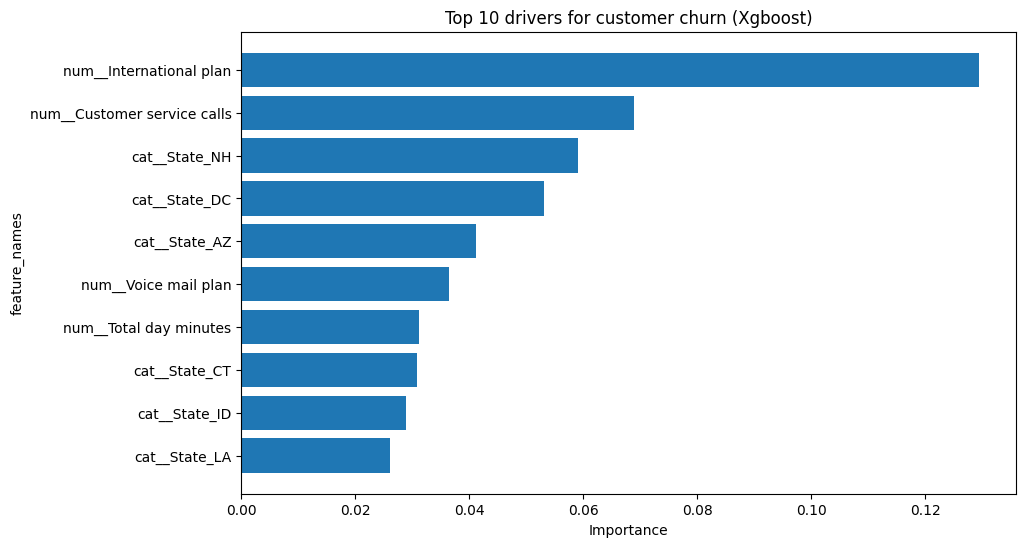

In [129]:
plt.figure(figsize=(10,6))
plt.barh(top_10_features["feature"],top_10_features["importance"])
plt.title("Top 10 drivers for customer churn (Xgboost)")
plt.xlabel("Importance")
plt.ylabel("feature_names")

As we can see here international plan is the main driver/reason for this model to churn following customer service call. This makes sense as many customer think international plan is overpriced, one reason to cancel subscribtion. Also more people calling customer service means that person has some issue and is a churner.

## Lets tune the model

In [130]:
from sklearn.model_selection import RandomizedSearchCV

In [131]:
param_grid={
    'classifier__max_depth': [3, 4, 5, 6, 7],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__n_estimators': [100, 200, 300],
    'classifier__subsample': [0.8, 0.9, 1.0]
}

In [132]:
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1  # Uses all your CPU cores to run faster
)

In [133]:
print("Tuning XGBoost... This might take a minute or two...")
random_search.fit(x, y)

Tuning XGBoost... This might take a minute or two...


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__learning_rate': [0.01, 0.05, ...], 'classifier__max_depth': [3, 4, ...], 'classifier__n_estimators': [100, 200, ...], 'classifier__subsample': [0.8, 0.9, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this

In [134]:
print(f"New Best F1-Score: {random_search.best_score_:.4f}")
print("Best Parameters:", random_search.best_params_)

New Best F1-Score: 0.8265
Best Parameters: {'classifier__subsample': 0.9, 'classifier__n_estimators': 100, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.2}


## Lets prepare the test dataset to see how my model performs

In [135]:
charge_cols = ['Total day charge', 'Total eve charge', 'Total night charge', 'Total intl charge']
df_test_cleaned = df_test.drop(columns=charge_cols).copy()

In [136]:
df_test["Area code"]=df_test_cleaned["Area code"].astype(str)

In [137]:
binary_cols = ['International plan', 'Voice mail plan']
for col in binary_cols:
    df_test_cleaned[col] = df_test_cleaned[col].map({'Yes': 1, 'No': 0})

In [138]:
x_test=df_test_cleaned.drop(columns=["Churn"])
y_test=le.transform(df_test_cleaned["Churn"])

In [139]:
best_model=random_search.best_estimator_

In [140]:
y_pred=best_model.predict(x_test)

In [141]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

Accuracy:  0.9460
Precision: 0.8172
Recall:    0.8000
F1-Score:  0.8085


As we can see that on our test data set it performed exceptionally well and got good accuracy and f1 score

In [142]:
cm=confusion_matrix(y_test, y_pred)

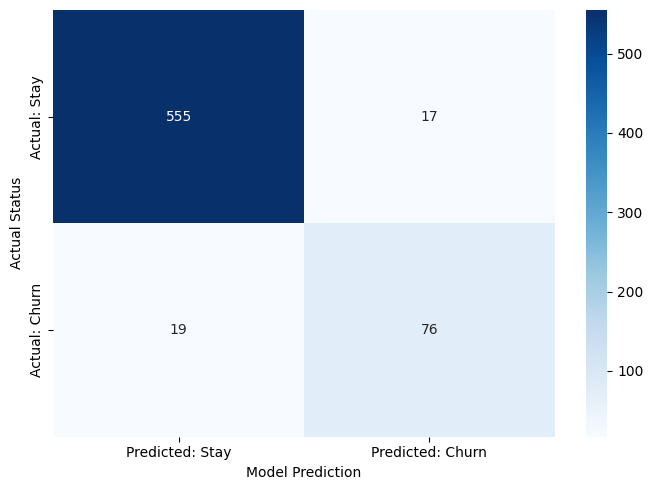

In [76]:
plt.figure(figsize=(7,5))
sns.heatmap(cm,annot=True,fmt="d",
           xticklabels=["Predicted: Stay","Predicted: Churn"],
           yticklabels=["Actual: Stay","Actual: Churn"],
           cmap="Blues")
plt.xlabel("Model Prediction")
plt.ylabel("Actual Status")
plt.tight_layout()

As we can see in confusion matrix false positive and false negitive is very less

In [78]:
import joblib

In [82]:
joblib.dump(best_model, r'D:\projects\Telecom Churn Prediction\Model\telecom_churn_pipeline.pkl')
joblib.dump(le, r'D:\projects\Telecom Churn Prediction\Model\label_encoder.pkl')

['D:\\projects\\Telecom Churn Prediction\\Model\\label_encoder.pkl']

In [83]:
test_probs = best_model.predict_proba(X_test)[:, 1]
df_test_export = df_test_cleaned.copy()
df_test_export['risk_score_%'] = np.round(test_probs * 100, 2)

In [84]:
conditions = [
    (df_test_export['risk_score_%'] < 30),
    (df_test_export['risk_score_%'] >= 30) & (df_test_export['risk_score_%'] < 70),
    (df_test_export['risk_score_%'] >= 70)
]

In [85]:
tiers = ['Low Risk', 'Medium Risk', 'High Risk']
df_test_export['risk_tier'] = np.select(conditions, tiers, default='Unknown')

In [86]:
df_test_export.to_csv(r'D:\projects\Telecom Churn Prediction\Dataset\scored_customers_test.csv', index=False)